### a) Đọc bộ dữ liệu train, test của MNIST từ Keras

In [1]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from tensorflow.keras.datasets import mnist

# Đọc bộ dữ liệu MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### b) In ra kích thước của tập train, test

In [2]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

print("Kích thước train_images:", train_images.shape)
print("Kích thước train_labels:", train_labels.shape)
print("Kích thước test_images:", test_images.shape)
print("Kích thước test_labels:", test_labels.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước train_images: (60000, 28, 28)
Kích thước train_labels: (60000,)
Kích thước test_images: (10000, 28, 28)
Kích thước test_labels: (10000,)


### c) Chuẩn hóa các giá trị pixel của ảnh về đoạn [0,1]

In [3]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Chuẩn hóa giá trị pixel về [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


### d) Định nghĩa hàm create_model

In [4]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

def create_model():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu'),
        Dropout(0.2),
        Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


### e) Huấn luyện mô hình bằng k-fold cross validation (với k=10)

In [5]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.model_selection import KFold
import numpy as np

# Định nghĩa KFold với n_splits = 10, shuffle = True, random_state = 42
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

fold_no = 1
for train_index, val_index in kfold.split(train_images):
    print(f"\n--- Đang huấn luyện Fold {fold_no}/10 ---")

    # Gán X_train_fold, X_val_fold, y_train_fold, y_val_fold
    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]

    # Gán model là kết quả của hàm create_model()
    model = create_model()

    # Huấn luyện mô hình (epoch = 5, batch_size = 32)
    history = model.fit(
        X_train_fold, y_train_fold,
        epochs=5,
        batch_size=32,
        validation_data=(X_val_fold, y_val_fold),
        verbose=1
    )

    # Lưu model huấn luyện được vào mảng models
    models.append(model)

    # Lấy accuracy và loss của fold hiện tại (lấy giá trị cuối cùng ở tập validation)
    val_loss = history.history['val_loss'][-1]
    val_acc = history.history['val_accuracy'][-1]

    print(f"Fold {fold_no} - Loss: {val_loss:.4f} - Accuracy: {val_acc*100:.2f}%")

    loss_per_fold.append(val_loss)
    accuracy_per_fold.append(val_acc)

    fold_no += 1

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------

--- Đang huấn luyện Fold 1/10 ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9110 - loss: 0.3044 - val_accuracy: 0.9580 - val_loss: 0.1431
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9556 - loss: 0.1499 - val_accuracy: 0.9732 - val_loss: 0.1018
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9658 - loss: 0.1138 - val_accuracy: 0.9760 - val_loss: 0.0835
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9723 - loss: 0.0907 - val_accuracy: 0.9777 - val_loss: 0.0783
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9756 - loss: 0.0764 - val_accuracy: 0.9782 - val_loss: 0.0713
Fold 1 - Loss: 0.0713 - Accuracy: 97.82%

--- Đang huấn luyện Fold 2/10 ---
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9126 - loss: 0.3026 - val_accuracy: 0.9543 - val_loss: 0.1569
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9564 - loss: 0.1463 - val_accuracy: 0.9680 - val_loss: 0.1117
Epoch 3/5
1688/168

### f) Tính và in ra Mean Accuracy, Standard deviation accuracy, Mean Loss, Standard deviation loss

In [6]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

mean_acc = np.mean(accuracy_per_fold)
std_acc = np.std(accuracy_per_fold)
mean_loss = np.mean(loss_per_fold)
std_loss = np.std(loss_per_fold)

print(f"Mean Accuracy: {mean_acc * 100:.2f}% (Std: {std_acc:.4f})")
print(f"Mean Loss: {mean_loss:.4f} (Std: {std_loss:.4f})")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Mean Accuracy: 97.48% (Std: 0.0019)
Mean Loss: 0.0860 (Std: 0.0087)


### g) Vẽ biểu đồ thể hiện accuracy, loss sau mỗi fold

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


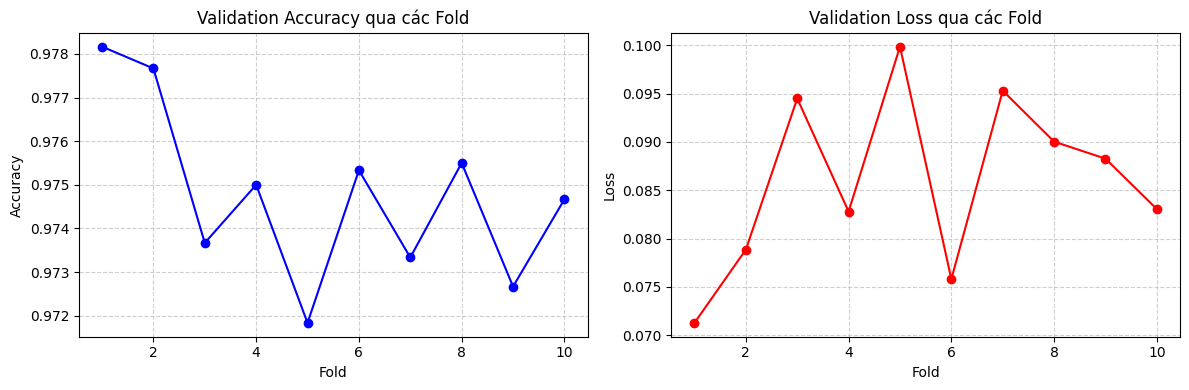

In [7]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import matplotlib.pyplot as plt

folds = range(1, 11)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(folds, accuracy_per_fold, marker='o', color='b')
plt.title('Validation Accuracy qua các Fold')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(folds, loss_per_fold, marker='o', color='r')
plt.title('Validation Loss qua các Fold')
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### h) Sử dụng mô hình có Accuracy tốt nhất giữa các fold và phân lớp cho tập test

In [8]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Tìm index có accuracy lớn nhất trong accuracy_per_fold
best_fold_index = np.argmax(accuracy_per_fold)
print(f"Fold có Accuracy tốt nhất là Fold {best_fold_index + 1} với Accuracy: {accuracy_per_fold[best_fold_index]*100:.2f}%")

# Lấy ra mô hình tốt nhất
best_model = models[best_fold_index]

# Dự đoán phân lớp cho tập test
y_pred_prob = best_model.predict(test_images)
y_pred = np.argmax(y_pred_prob, axis=1)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Fold có Accuracy tốt nhất là Fold 1 với Accuracy: 97.82%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


### i) Tính và in ra Accuracy của mô hình trên tập test

In [9]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(test_labels, y_pred)
print(f"Accuracy của mô hình tốt nhất trên tập test: {test_accuracy * 100:.2f}%")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy của mô hình tốt nhất trên tập test: 97.77%


### j) Tính và in ra Precision, Recall, F1-score của từng lớp và trung bình của mô hình trên tập test

In [10]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.metrics import classification_report

print("Classification Report trên tập test:")
print(classification_report(test_labels, y_pred))

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Classification Report trên tập test:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.97      1032
           3       0.97      0.98      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.97      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.97      0.97      1028
           8       0.96      0.98      0.97       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



### k) Hiển thị confusion matrix bằng heat map (bản đồ nhiệt)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


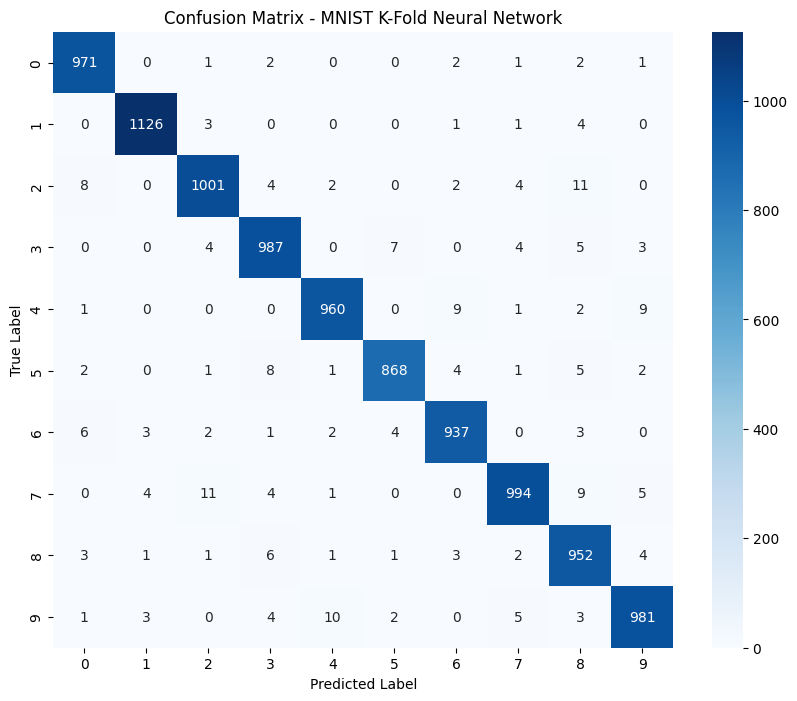

In [11]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix - MNIST K-Fold Neural Network')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### l) In ra kết quả phân lớp của 05 ảnh đầu tiên trong tập test

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Ảnh 1 -> Nhãn thực tế: 7 | Nhãn dự đoán: 7
Ảnh 2 -> Nhãn thực tế: 2 | Nhãn dự đoán: 2
Ảnh 3 -> Nhãn thực tế: 1 | Nhãn dự đoán: 1
Ảnh 4 -> Nhãn thực tế: 0 | Nhãn dự đoán: 0
Ảnh 5 -> Nhãn thực tế: 4 | Nhãn dự đoán: 4


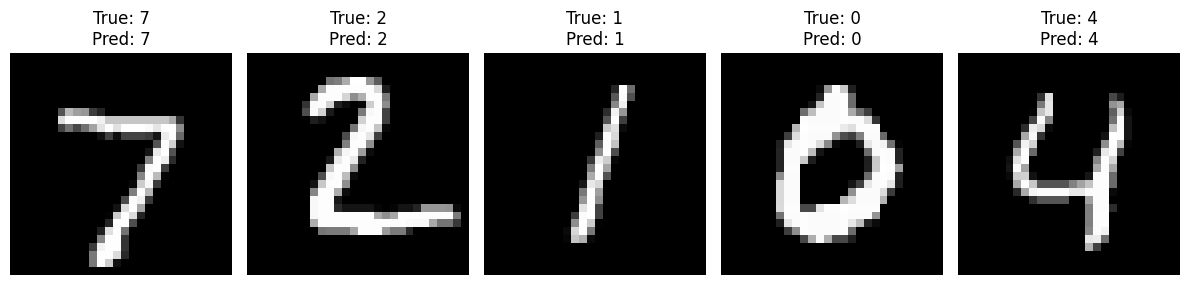

In [12]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.figure(figsize=(12, 3))
for i in range(5):
    img = test_images[i]
    true_label = test_labels[i]
    pred_label = y_pred[i]

    print(f"Ảnh {i+1} -> Nhãn thực tế: {true_label} | Nhãn dự đoán: {pred_label}")

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis('off')

plt.tight_layout()
plt.show()